# Studying PBO in finite samples

Repeated controlled samples estimate the mean PBO and the uncertainty of that simulation mean:

$$
\overline\phi_M=\frac{1}{M}\sum_{m=1}^{M}\widehat\phi^{(m)},
\qquad
\widehat{\operatorname{SE}}(\overline\phi_M)=\frac{s_\phi}{\sqrt M}.
$$

Here, $M$ is the number of simulated samples, $\widehat\phi^{(m)}$ is the PBO in sample $m$, $\overline\phi_M$ is their mean, and $s_\phi$ is their sample standard deviation. Simulation is used because public history does not reveal repeated samples or the true presence of an edge.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("19_backtest_overfitting");
using CSV, TOML, Printf, Combinatorics
using RiskLabAI.Backtest: probability_of_backtest_overfitting
using RiskLabAI.Validation: bagged_probability_of_backtest_overfitting,adaptive_probability_of_backtest_overfitting
prefix = "sensitivity"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter19-"*replace(name,"_"=>"-"))

function read_primitive(name)
    root = joinpath("..","data","chapter19_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".csv"]
    path = joinpath(root,name*".csv")
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values)==(metadata["rows"],metadata["columns"])
    return values
end

function time_groups(count,partitions)
    base,remaining = divrem(count,partitions)
    boundaries = cumsum(vcat(0,[base+(index<=remaining) for index in 1:partitions]))
    return [collect(boundaries[index]+1:boundaries[index+1]) for index in 1:partitions]
end

function score_vector(values)
    deviations,means = vec(std(values;dims=1,corrected=false)),vec(mean(values;dims=1))
    return [deviation>0 ? average/deviation : 0. for (average,deviation) in zip(means,deviations)]
end

function cscv_records(values,partitions;names=["Trial "*string(index) for index in axes(values,2)],key=nothing)
    groups = time_groups(size(values,1),partitions)
    records = NamedTuple[]
    for (number,train_groups) in enumerate(combinations(1:partitions,partitions÷2))
        test_groups = setdiff(1:partitions,train_groups)
        train,test = reduce(vcat,groups[train_groups]),reduce(vcat,groups[test_groups])
        training_scores,testing_scores = score_vector(values[train,:]),score_vector(values[test,:])
        selected = argmax(training_scores)
        ranks = invperm(sortperm(testing_scores))
        rank = ranks[selected]
        relative = rank/(size(values,2)+1)
        logit = log(relative/(1-relative))
        push!(records,(combination=number,train=join(train_groups,", "),test=join(test_groups,", "),n_train=length(train),n_test=length(test),selected=selected,name=names[selected],in_sample=training_scores[selected],out_sample=testing_scores[selected],rank=rank,relative=relative,logit=logit,overfit=Int(logit<=0)))
    end
    result = DataFrame(records)
    rename!(result,["Combination","Training groups","Testing groups","Training observations","Testing observations","Selected trial","Selected name","In-sample score","Out-of-sample score","Out-of-sample rank","Relative rank","Logit","Overfit"])
    key===nothing || save_data(result,paths,key*"_records")
    return result
end

function manual_pbo(values,partitions)
    records = cscv_records(values,partitions)
    return mean(records.Overfit),records.Logit
end

function histogram_panel(values,bins,color,key;density=false,title_text="")
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = zeros(Int,bins)
    for value in values
        counts[searchsortedlast(edges,value)] += 1
    end
    widths = diff(edges)
    heights = density ? counts./sum(counts)./widths : Float64.(counts)
    @assert sum(counts)==length(values)
    save_data(DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts,height=heights),paths,key*"_histogram")
    panel = bar((edges[1:end-1].+edges[2:end])./2,heights;bar_width=widths,color,fillalpha=.9,linecolor=palette.background,label="",xlabel="Logit",ylabel=density ? "Density" : "Combinations",title=title_text)
    vline!(panel,[0.];color=palette.rose,label="",linewidth=1.5)
    return panel
end

function average_ranks(values)
    order = sortperm(values)
    ranks = zeros(length(values))
    first_position = 1
    while first_position<=length(values)
        last_position = first_position
        while last_position<length(values) && values[order[last_position+1]]==values[order[first_position]]
            last_position += 1
        end
        ranks[order[first_position:last_position]] .= (first_position+last_position)/2
        first_position = last_position+1
    end
    return ranks
end


average_ranks (generic function with 1 method)

## Public Sensitivity

Row,Trials,Time groups,Logits,PBO,Mean logit,Logit spread
,Int64,Int64,Int64,Float64,Float64,Float64
1,4,4,6,0.333333,0.62557,1.21864
2,4,6,20,0.35,0.170681,1.07696
3,4,8,70,0.342857,0.253539,0.888399
4,4,10,252,0.246032,0.571815,0.847931
5,4,12,924,0.416667,0.184343,0.978215
6,8,4,6,0.333333,0.290495,1.70678
7,8,6,20,0.45,0.036942,0.861709
8,8,8,70,0.428571,0.0552586,1.04585
9,8,10,252,0.34127,0.335861,0.971387


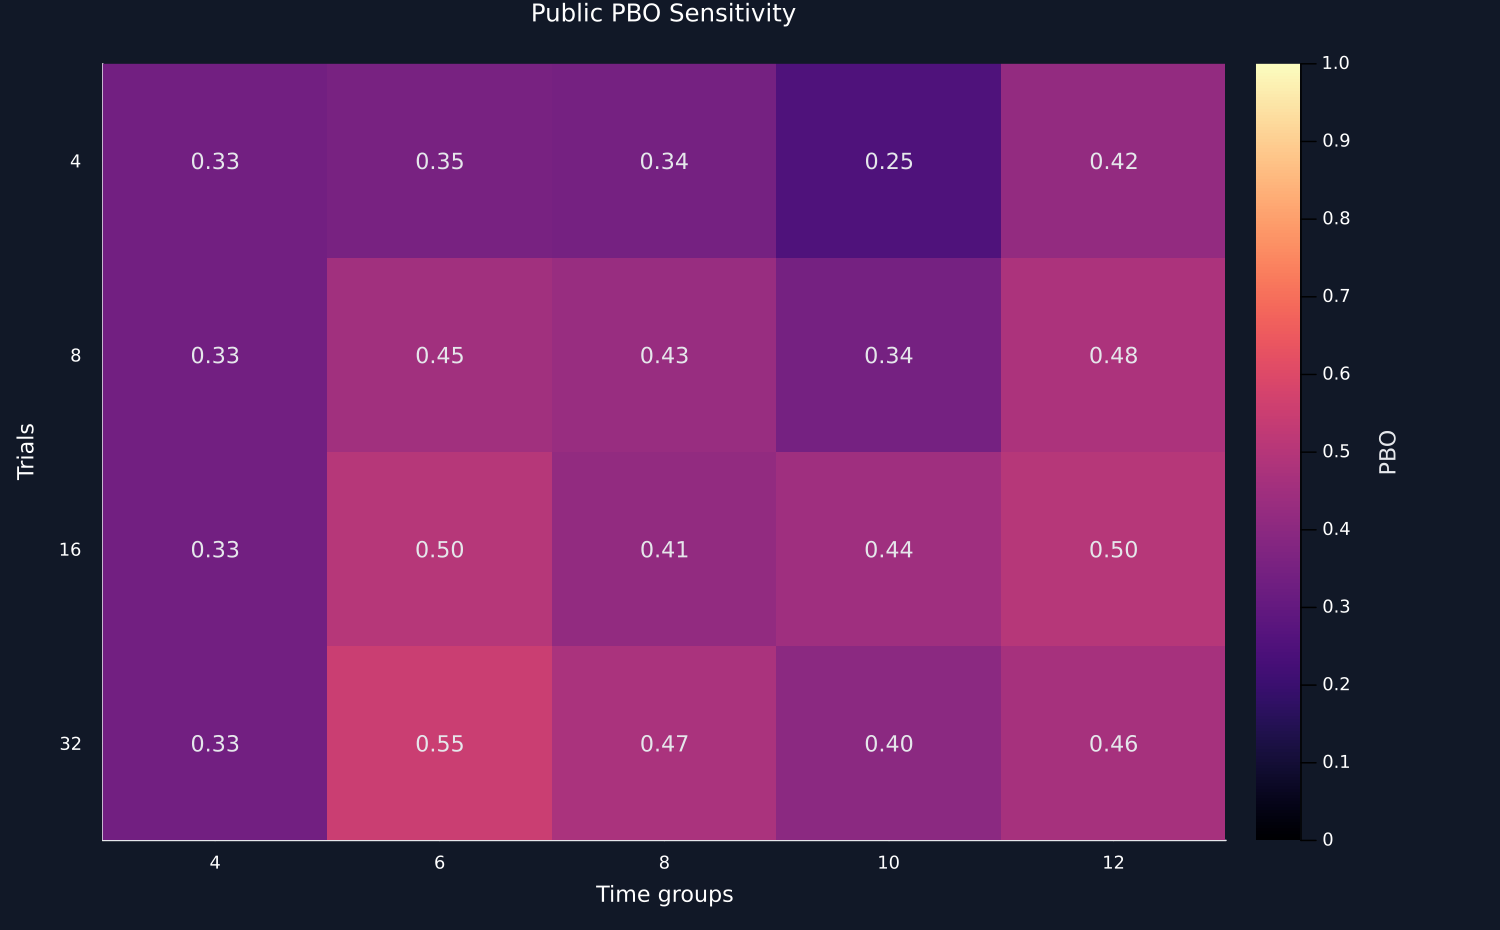

In [2]:
partition_choices,trial_choices = [4,6,8,10,12],[4,8,16,32]
sensitivity_rows = NamedTuple[]
for trial_count in trial_choices
    chosen = unique(round.(Int,range(0,31;length=trial_count))).+1
    values = performances[:,chosen]
    for partitions in partition_choices
        records = cscv_records(values,partitions;key="sensitivity_"*string(trial_count)*"_"*string(partitions))
        push!(sensitivity_rows,(trials=length(chosen),groups=partitions,logits=nrow(records),pbo=mean(records.Overfit),mean=mean(records.Logit),spread=std(records.Logit)))
    end
end
public_sensitivity = DataFrame(sensitivity_rows)
rename!(public_sensitivity,["Trials","Time groups","Logits","PBO","Mean logit","Logit spread"])
table(public_sensitivity,"public_sensitivity","Public PBO sensitivity to the trial count and time-group count.")
values = permutedims(reshape(public_sensitivity.PBO,5,4))
figure = heatmap(1:5,1:4,values;color=:magma,clims=(0,1),colorbar_title="PBO",xticks=(1:5,string.(partition_choices)),yticks=(1:4,string.(trial_choices)),yflip=true,title="Public PBO Sensitivity",xlabel="Time groups",ylabel="Trials",size=(1000,620),right_margin=15Plots.mm,grid=false)
for row in 1:4, column in 1:5
    annotate!(figure,column,row,text(@sprintf("%.2f",values[row,column]),10,values[row,column]>.75 ? palette.background : palette.text,:center))
end
save_figure(figure,paths,"public_pbo_sensitivity")


The number of logits grows quickly with the number of time groups:

$$
C_S=\binom{S}{S/2},
\qquad
C_{S+2}=C_S\frac{(S+2)(S+1)}{(S/2+1)^2}.
$$

Here, $S$ is an even number of time groups, $C_S$ is the resulting number of logits, and the second expression gives the exact growth when two groups are added.

## Controlled Experiments

Each simulated trial combines a common shock, its own shock, time-varying volatility, and a declared mean pattern:

$$
R_{t,n}=\sigma_t\left(\sqrt\rho\,Z_t+\sqrt{1-\rho}\,\varepsilon_{t,n}\right)+\mu_{t,n}.
$$

Here, $R_{t,n}$ is the return of trial $n$ at time $t$, $\sigma_t$ is a changing volatility scale, $\rho$ is the common-shock share, $Z_t$ is a shock shared by all trials, $\varepsilon_{t,n}$ is a trial-specific shock, and $\mu_{t,n}$ is the known mean pattern used to create no edge, one persistent edge, or a reversal.

Row,Condition,Known mean pattern,Trials,Time groups,Repetitions per sample size
,String,String,Int64,Int64,Int64
1,No edge,Every trial has zero mean,16,8,40
2,Persistent edge,Trial 1 has mean 0.0015 throughout,16,8,40
3,Reversing edge,Trial 1 leads in the first 75 percent and trial 16 leads in the last 25 percent,16,8,40


Row,Condition,Observations,Mean PBO,PBO spread,Mean logit,Simulation standard error
,String,Int64,Float64,Float64,Float64,Float64
1,No edge,120,0.527143,0.220052,-0.0618876,0.0347933
2,No edge,240,0.463214,0.23766,0.128369,0.0375774
3,No edge,480,0.445,0.203361,0.147467,0.0321543
4,No edge,960,0.57,0.192611,-0.171346,0.0304544
5,Persistent edge,120,0.427143,0.206736,0.210155,0.0326879
6,Persistent edge,240,0.352143,0.205129,0.614528,0.0324338
7,Persistent edge,480,0.269286,0.225054,1.14926,0.0355842
8,Persistent edge,960,0.129286,0.15649,1.86958,0.0247433
9,Reversing edge,120,0.38,0.180696,0.328329,0.0285705


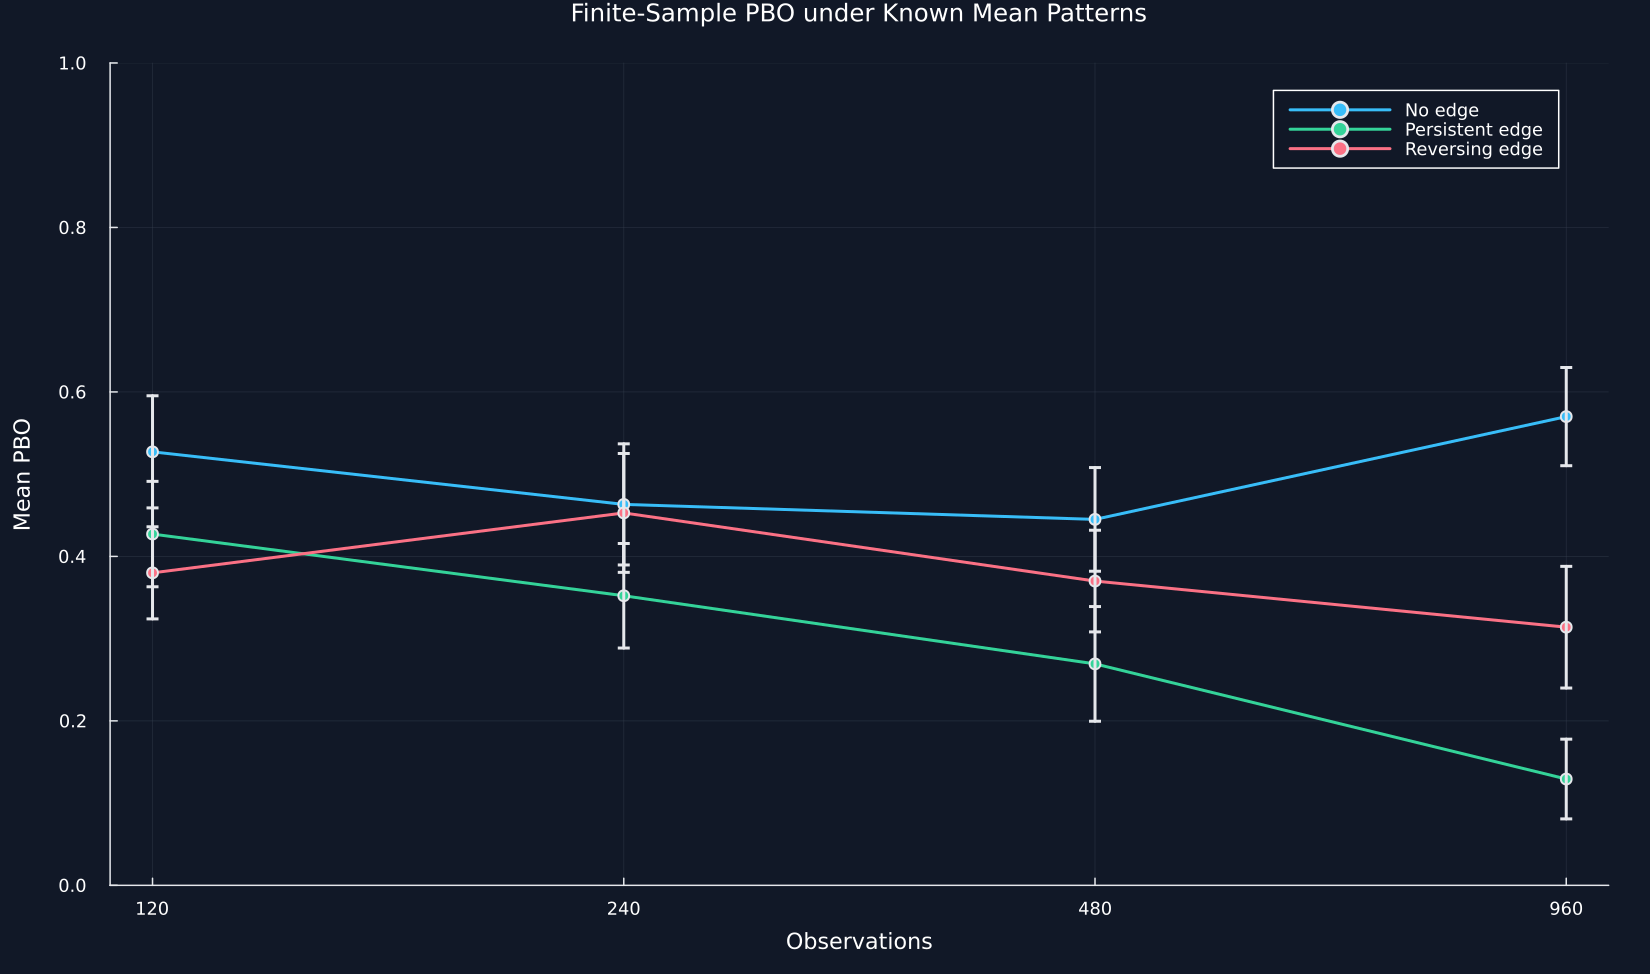

In [3]:
conditions = ["No edge","Persistent edge","Reversing edge"]
sample_sizes = [120,240,480,960]
simulation_design = DataFrame("Condition"=>conditions,"Known mean pattern"=>["Every trial has zero mean","Trial 1 has mean 0.0015 throughout","Trial 1 leads in the first 75 percent and trial 16 leads in the last 25 percent"],"Trials"=>fill(16,3),"Time groups"=>fill(8,3),"Repetitions per sample size"=>fill(40,3))
simulation_rows = NamedTuple[]
simulation_logits = DataFrame(condition=String[],observations=Int[],repetition=Int[],combination=Int[],logit=Float64[])
for (condition_index,condition) in enumerate(conditions), observations in sample_sizes, repetition in 1:40
    primitives = read_primitive("simulation_"*string(condition_index-1)*"_"*string(observations)*"_"*string(repetition))
    log_scale = zeros(observations)
    for index in 2:observations
        log_scale[index] = .96*log_scale[index-1]+primitives[index,1]
    end
    scales = 0.01 .* exp.(clamp.(log_scale,-1.,1.))
    values = scales.*(sqrt(.30).*primitives[:,2].+sqrt(.70).*primitives[:,3:end])
    if condition=="Persistent edge"
        values[:,1] .+= .0015
    elseif condition=="Reversing edge"
        boundary = floor(Int,.75*observations)
        values[1:boundary,1] .+= .0015
        values[boundary+1:end,end] .+= .0025
        values[boundary+1:end,:] .*= 1.6
    end
    value,logits = manual_pbo(values,8)
    push!(simulation_rows,(condition=condition,observations=observations,repetition=repetition,pbo=value,logit=mean(logits)))
    append!(simulation_logits,DataFrame(condition=fill(condition,70),observations=fill(observations,70),repetition=fill(repetition,70),combination=collect(1:70),logit=logits))
end
simulation_results = DataFrame(simulation_rows)
rename!(simulation_results,["Condition","Observations","Repetition","PBO","Mean logit"])
finite_sample_summary = combine(groupby(simulation_results,["Condition","Observations"];sort=true),"PBO"=>mean=>"Mean PBO","PBO"=>std=>"PBO spread","Mean logit"=>mean=>"Mean logit")
finite_sample_summary[!,"Simulation standard error"] = finite_sample_summary[!,"PBO spread"]./sqrt(40)
table(simulation_design,"simulation_design","Known-truth designs for the finite-sample study.")
table(finite_sample_summary,"finite_sample_summary","Mean PBO across controlled repeated samples.")
CSV.write(joinpath(paths.tables,"finite_sample_repetitions.csv"),simulation_results)
save_data(simulation_logits,paths,"simulation_logits")
figure = plot(;title="Finite-Sample PBO under Known Mean Patterns",xlabel="Observations",ylabel="Mean PBO",xscale=:log2,xticks=(sample_sizes,string.(sample_sizes)),ylims=(0,1),size=(1100,650),legend=:topright)
for (condition,color) in zip(conditions,[palette.cyan,palette.green,palette.rose])
    current = finite_sample_summary[finite_sample_summary.Condition.==condition,:]
    plot!(figure,current.Observations,current[!,"Mean PBO"];yerror=1.96.*current[!,"Simulation standard error"],marker=:circle,color,label=condition,linewidth=2)
end
save_figure(figure,paths,"finite_sample_behavior")


## Comparing bagged estimates with adaptive estimates

A bagged PBO estimate averages the estimates from repeated moving-block resamples:

$$
\widehat\phi_{\mathrm{bag}}
=\frac{1}{B}\sum_{b=1}^{B}\widehat\phi_b.
$$

Here, $B$ is the number of block resamples, $\widehat\phi_b$ is the PBO from resample $b$, and $\widehat\phi_{\mathrm{bag}}$ is their average. Consecutive rows remain together inside each sampled block so short-run order is partly preserved.

Row,Quantity,Value
,String,Float64
1,Plain mean,0.32381
2,Plain spread,0.162708
3,Bagged mean,0.241
4,Bagged spread,0.0738983
5,Adaptive PBO for seed 3,0.46237
6,Adaptive selected index for seed 3,6.0


Row,Calculation,PBO,Repeated estimates,Selected trial
,String,Float64,Int64,String
1,Plain,0.471429,1,Not applicable
2,Bagged,0.316786,40,Not applicable
3,Adaptive,0.456211,1,27


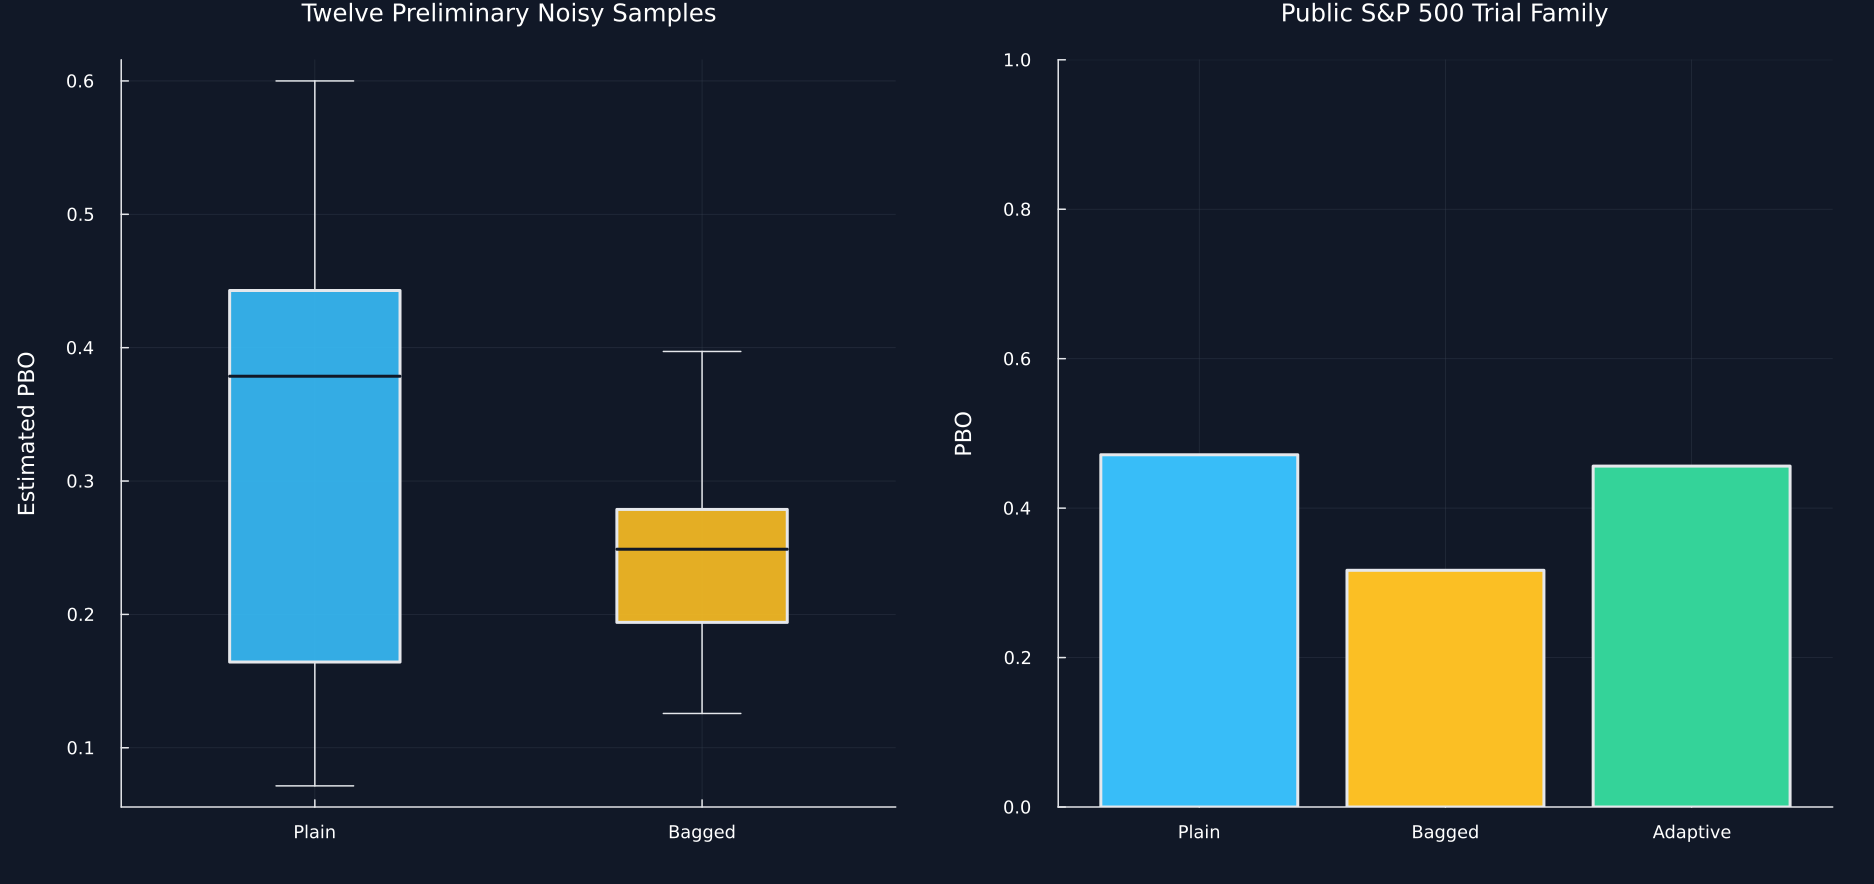

In [4]:
noisy_values(seed) = read_primitive("noisy_"*string(seed)) .* 0.05 .+ permutedims(collect(range(0,.004;length=8)))
noisy_rows = collect(eachcol(Int.(read_primitive("noisy_bootstrap"))))
plain_values,bagged_values = Float64[],Float64[]
noisy_bags = DataFrame(seed=Int[],bag=Int[],pbo=Float64[])
for seed in 0:11
    values = noisy_values(seed)
    plain,logits = probability_of_backtest_overfitting(values;n_partitions=8)
    bagged,bags = bagged_probability_of_backtest_overfitting(values;n_partitions=8,n_bag=25,bootstrap_rows=noisy_rows)
    push!(plain_values,plain)
    push!(bagged_values,bagged)
    append!(noisy_bags,DataFrame(seed=fill(seed,25),bag=collect(1:25),pbo=bags))
    save_data(DataFrame(logit=logits),paths,"noisy_"*string(seed)*"_logits")
end
save_data(noisy_bags,paths,"noisy_bag_values")
save_data(DataFrame(seed=collect(0:11),plain=plain_values,bagged=bagged_values),paths,"noisy_variant_values")
adaptive_preliminary_pbo,adaptive_preliminary_trial = adaptive_probability_of_backtest_overfitting(noisy_values(3);n_partitions=8)
preliminary_variant_reproduction = DataFrame("Quantity"=>["Plain mean","Plain spread","Bagged mean","Bagged spread","Adaptive PBO for seed 3","Adaptive selected index for seed 3"],"Value"=>[mean(plain_values),std(plain_values;corrected=false),mean(bagged_values),std(bagged_values;corrected=false),adaptive_preliminary_pbo,adaptive_preliminary_trial-1])
public_plain,public_plain_logits = probability_of_backtest_overfitting(performances;n_partitions=8)
public_rows = collect(eachcol(Int.(read_primitive("public_bootstrap"))))
public_bagged,public_bag_values = bagged_probability_of_backtest_overfitting(performances;n_partitions=8,n_bag=40,bootstrap_rows=public_rows)
public_adaptive,public_adaptive_trial = adaptive_probability_of_backtest_overfitting(performances;n_partitions=8)
public_variants = DataFrame("Calculation"=>["Plain","Bagged","Adaptive"],"PBO"=>[public_plain,public_bagged,public_adaptive],"Repeated estimates"=>[1,40,1],"Selected trial"=>["Not applicable","Not applicable",string(public_adaptive_trial)])
table(preliminary_variant_reproduction,"preliminary_variant_reproduction","Reproduction of the preliminary plain, bagged, and adaptive calculation; the preliminary selected-index row retains the original zero-based label.")
table(public_variants,"public_variant_comparison","Plain, bagged, and adaptive PBO on the public trials.")
save_data(DataFrame(bag=collect(1:40),pbo=public_bag_values),paths,"public_bag_values")
p1 = plot(;xticks=([1,2],["Plain","Bagged"]),xlims=(.5,2.5),ylabel="Estimated PBO",title="Twelve Preliminary Noisy Samples",legend=false)
for (position,values,color) in [(1,plain_values,palette.cyan),(2,bagged_values,palette.amber)]
    q1,median_value,q3 = quantile(values,[.25,.5,.75])
    lower = minimum(filter(>=(q1-1.5*(q3-q1)),values))
    upper = maximum(filter(<=(q3+1.5*(q3-q1)),values))
    plot!(p1,Shape([position-.22,position+.22,position+.22,position-.22],[q1,q1,q3,q3]);color,fillalpha=.9,linecolor=palette.text)
    plot!(p1,[position-.22,position+.22],[median_value,median_value];color=palette.background,linewidth=2)
    plot!(p1,[position,position],[lower,q1];color=palette.text,linewidth=1)
    plot!(p1,[position,position],[q3,upper];color=palette.text,linewidth=1)
    plot!(p1,[position-.1,position+.1],[lower,lower];color=palette.text,linewidth=1)
    plot!(p1,[position-.1,position+.1],[upper,upper];color=palette.text,linewidth=1)
    outside = filter(value->value<lower||value>upper,values)
    scatter!(p1,fill(position,length(outside)),outside;color=palette.text,markersize=4)
end
p2 = bar(public_variants.Calculation,public_variants.PBO;color=[palette.cyan,palette.amber,palette.green],label="",ylims=(0,1),ylabel="PBO",title="Public S&P 500 Trial Family")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,590),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"bagged_adaptive_comparison")


## Calculation Growth

Row,Time groups,Logits,PBO,Median seconds,Smallest seconds,Largest seconds,Seconds per logit
,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,4,6,1.0,0.0001859,0.0001567,0.000226,3.09833e-5
2,6,20,0.95,0.0007927,0.0007705,0.0009133,3.9635e-5
3,8,70,0.942857,0.003527,0.0032681,0.0041209,5.03857e-5
4,10,252,0.952381,0.0157334,0.0141252,0.0249234,6.24341e-5
5,12,924,0.92316,0.0825369,0.0733203,0.101586,8.93256e-5


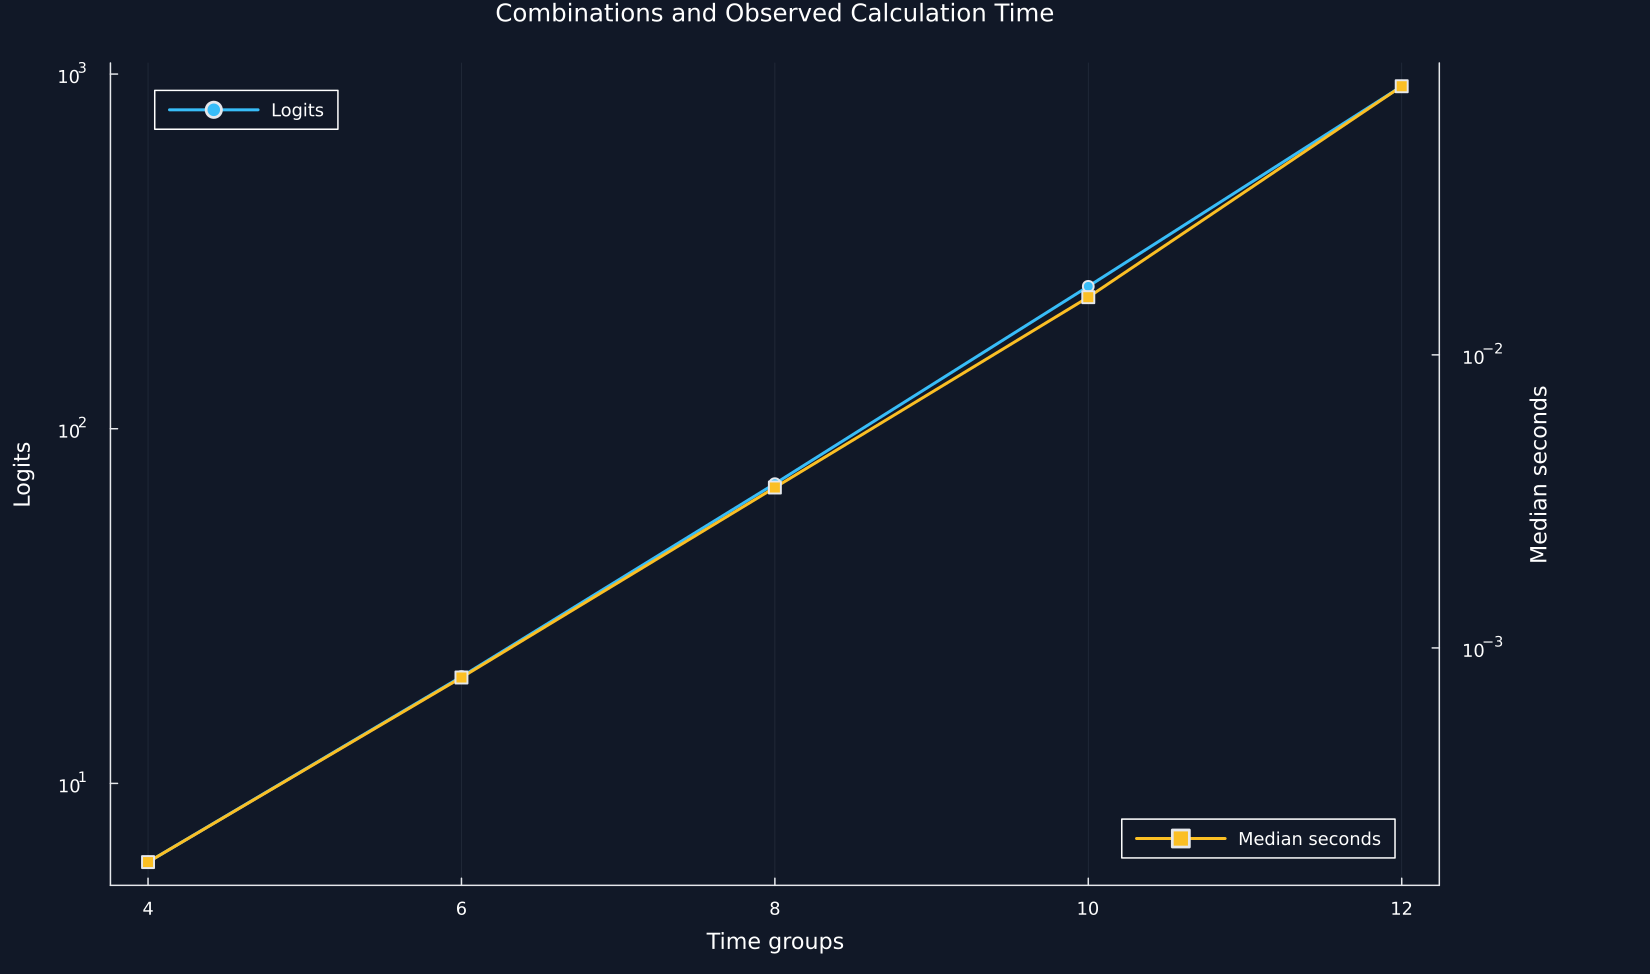

In [5]:
function benchmark_rank_order(values)
    length(values)==16 && all(isfinite,values) || throw(ArgumentError("The benchmark requires sixteen finite scores."))
    order = collect(1:16)
    function exchange!(left,right)
        if values[order[left]]>values[order[right]]
            order[left],order[right] = order[right],order[left]
        end
    end
    width = 2
    while width<=16
        for first in 1:width:16
            for offset in 0:width÷2-1
                exchange!(first+offset,first+width-1-offset)
            end
            step = width÷4
            while step>0
                for start in first:2step:first+width-1, offset in 0:step-1
                    exchange!(start+offset,start+offset+step)
                end
                step ÷= 2
            end
        end
        width *= 2
    end
    return order
end

benchmark_matrix = performances[1:480,1:16]
probability_of_backtest_overfitting(benchmark_matrix;n_partitions=4,rank_order=benchmark_rank_order)
timing_rows = NamedTuple[]
for partitions in [4,6,8,10,12]
    elapsed = Float64[]
    result = nothing
    for repetition in 1:3
        seconds = @elapsed result = probability_of_backtest_overfitting(benchmark_matrix;n_partitions=partitions,rank_order=benchmark_rank_order)
        push!(elapsed,seconds)
    end
    value,logits = result
    push!(timing_rows,(groups=partitions,logits=length(logits),pbo=value,median=median(elapsed),smallest=minimum(elapsed),largest=maximum(elapsed),per_logit=median(elapsed)/length(logits)))
    save_data(DataFrame(repetition=collect(1:3),seconds=elapsed),paths,"timings_"*string(partitions))
    save_data(DataFrame(logit=logits),paths,"benchmark_"*string(partitions)*"_logits")
end
calculation_growth = DataFrame(timing_rows)
rename!(calculation_growth,["Time groups","Logits","PBO","Median seconds","Smallest seconds","Largest seconds","Seconds per logit"])
table(calculation_growth,"calculation_growth","Observed native calculation growth for one fixed matrix, with a native comparison network preserving NumPy's tied-score order for the sixteen benchmark trials.")
figure = plot(calculation_growth[!,"Time groups"],calculation_growth.Logits;color=palette.cyan,marker=:circle,label="Logits",yscale=:log10,xlabel="Time groups",ylabel="Logits",title="Combinations and Observed Calculation Time",xticks=[4,6,8,10,12],legend=:topleft,size=(1100,650),right_margin=20Plots.mm)
right = twinx(figure)
plot!(right,calculation_growth[!,"Time groups"],calculation_growth[!,"Median seconds"];color=palette.amber,marker=:rect,label="Median seconds",yscale=:log10,ylabel="Median seconds",legend=:bottomright,grid=false)
save_figure(figure,paths,"calculation_growth")


## Tests

In [6]:
@assert size(public_sensitivity)==(20,6)
@assert all(value->0<=value<=1,public_sensitivity.PBO)
@assert public_sensitivity.Logits==[binomial(value,value÷2) for value in public_sensitivity[!,"Time groups"]]
@assert size(simulation_results)==(480,5)
@assert size(finite_sample_summary)==(12,6)
@assert all(value->0<=value<=1,finite_sample_summary[!,"Mean PBO"])
@assert all(>=(0),finite_sample_summary[!,"Simulation standard error"])
@assert round(mean(plain_values);digits=3)==.324
@assert round(std(plain_values;corrected=false);digits=3)==.163
@assert round(mean(bagged_values);digits=3)==.241
@assert round(std(bagged_values;corrected=false);digits=3)==.074
@assert round(adaptive_preliminary_pbo;digits=3)==.462
@assert adaptive_preliminary_trial==7
@assert std(bagged_values)<std(plain_values)
@assert all(value->0<=value<=1,public_variants.PBO)
@assert length(public_bag_values)==40
@assert calculation_growth.Logits==[6,20,70,252,924]
@assert all(>(0),calculation_growth[!,"Median seconds"])
@assert public_variants[!,"Selected trial"]==["Not applicable","Not applicable",string(public_adaptive_trial)]
@assert isfile(joinpath(paths.figures,"public_pbo_sensitivity.pdf"))
@assert isfile(joinpath(paths.figures,"finite_sample_behavior.pdf"))
@assert isfile(joinpath(paths.figures,"bagged_adaptive_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"calculation_growth.pdf"))
@assert isfile(joinpath(paths.tables,"public_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"simulation_design.tex"))
@assert isfile(joinpath(paths.tables,"finite_sample_summary.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_variant_reproduction.tex"))
@assert isfile(joinpath(paths.tables,"public_variant_comparison.tex"))
@assert isfile(joinpath(paths.tables,"calculation_growth.tex"))
